Project Machine Learning
Analisis dan Persiapan Data Transaksi Penjualan Kedai Kopi (Coffee Shop Sales)

Nama : Iqsa Purnama Saputra  
Program Studi : Teknik Informatika, Universitas Pamulang  
Cakupan : Data Loading → Data Cleaning → Transformasi → EDA & ExDA → Data Splitting

1. Data Collecting

Sumber dataset : Kaggle, Coffee Shop Sales Analysis (divu2001)  
https://www.kaggle.com/datasets/divu2001/coffee-shop-sales-analysis
File Dataset : data/Project.csv


2. Import Library dan Data Loading

In [1]:
import pandas as pd                # pandas      : mengolah data berbentuk tabel
import numpy as np                 # numpy       : hitungan angka
import matplotlib.pyplot as plt    # matplotlib  : membuat grafik
import seaborn as sns              # seaborn     : grafik yang lebih rapi
import sklearn                     # scikit-learn: encoding, scaling, dan split data

print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("scikit-learn:", sklearn.__version__)

pandas      : 3.0.5
numpy       : 2.5.2
scikit-learn: 1.9.1


In [2]:
df = pd.read_csv("data/Project.csv")      # baca file CSV

print("Jumlah baris dan kolom:", df.shape)  # (jumlah baris, jumlah kolom)
df.head()                                   # tampilkan 5 baris pertama

Jumlah baris dan kolom: (149116, 18)


,transaction_id,transaction_date,transaction_time,store_id,store_location,product_id,transaction_qty,unit_price,Total_Bill,product_category,product_type,product_detail,Size,Month Name,Day Name,Hour,Month,Day of Week
0,114301,01-06-2023,11:33:29,3,Astoria,45,1,3.0,3.0,Tea,Brewed herbal tea,Peppermint,Large,June,Thursday,11,6,3
1,115405,02-06-2023,11:18:24,3,Astoria,45,1,3.0,3.0,Tea,Brewed herbal tea,Peppermint,Large,June,Friday,11,6,4
2,115478,02-06-2023,12:02:45,3,Astoria,45,1,3.0,3.0,Tea,Brewed herbal tea,Peppermint,Large,June,Friday,12,6,4
3,116288,02-06-2023,19:39:47,3,Astoria,45,1,3.0,3.0,Tea,Brewed herbal tea,Peppermint,Large,June,Friday,19,6,4
4,116714,03-06-2023,12:24:57,3,Astoria,45,1,3.0,3.0,Tea,Brewed herbal tea,Peppermint,Large,June,Saturday,12,6,5


## 3. Data Cleaning

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   transaction_id    149116 non-null  int64  
 1   transaction_date  149116 non-null  str    
 2   transaction_time  149116 non-null  str    
 3   store_id          149116 non-null  int64  
 4   store_location    149116 non-null  str    
 5   product_id        149116 non-null  int64  
 6   transaction_qty   149116 non-null  int64  
 7   unit_price        149116 non-null  float64
 8   Total_Bill        149116 non-null  float64
 9   product_category  149116 non-null  str    
 10  product_type      149116 non-null  str    
 11  product_detail    149116 non-null  str    
 12  Size              149116 non-null  str    
 13  Month Name        149116 non-null  str    
 14  Day Name          149116 non-null  str    
 15  Hour              149116 non-null  int64  
 16  Month             149116 non-nu

In [4]:
display(df.describe())                               # statistik kolom angka
display(df.select_dtypes(exclude="number").describe())  # ringkasan kolom teks

,transaction_id,store_id,product_id,transaction_qty,unit_price,Total_Bill,Hour,Month,Day of Week
count,149116.000000,149116.000000,149116.000000,149116.000000,149116.000000,149116.000000,149116.000000,149116.000000,149116.000000
mean,74737.371872,5.342063,47.918607,1.438276,3.382219,4.686367,11.735790,3.988881,2.982336
std,43153.600016,2.074241,17.930020,0.542509,2.658723,4.227099,3.764662,1.673091,1.996650
min,1.000000,3.000000,1.000000,1.000000,0.800000,0.800000,6.000000,1.000000,0.000000
25%,37335.750000,3.000000,33.000000,1.000000,2.500000,3.000000,9.000000,3.000000,1.000000
50%,74727.500000,5.000000,47.000000,1.000000,3.000000,3.750000,11.000000,4.000000,3.000000
75%,112094.250000,8.000000,60.000000,2.000000,3.750000,6.000000,15.000000,5.000000,5.000000
max,149456.000000,8.000000,87.000000,8.000000,45.000000,360.000000,20.000000,6.000000,6.000000


,transaction_date,transaction_time,store_location,product_category,product_type,product_detail,Size,Month Name,Day Name
count,149116,149116,149116,149116,149116,149116,149116,149116,149116
unique,181,25762,3,9,29,45,4,6,7
top,19-06-2023,09:31:15,Hell's Kitchen,Coffee,Brewed Chai tea,Our Old Time Diner Blend,Regular,June,Friday
freq,1343,41,50735,58416,17183,8660,45789,35352,21701


In [5]:
print("Total missing value :", df.isnull().sum().sum())
print("Jumlah baris duplikat:", df.duplicated().sum())

Total missing value : 0
Jumlah baris duplikat: 0


In [6]:
tanggal = pd.to_datetime(df["transaction_date"], format="%d-%m-%Y")
print("Tanggal awal :", tanggal.min())
print("Tanggal akhir:", tanggal.max())

Tanggal awal : 2023-01-01 00:00:00
Tanggal akhir: 2023-06-30 00:00:00


transaction_qty: 36 outlier (batas -0.50 - 3.50)
unit_price: 4212 outlier (batas 0.62 - 5.62)
Total_Bill: 3273 outlier (batas -1.50 - 10.50)


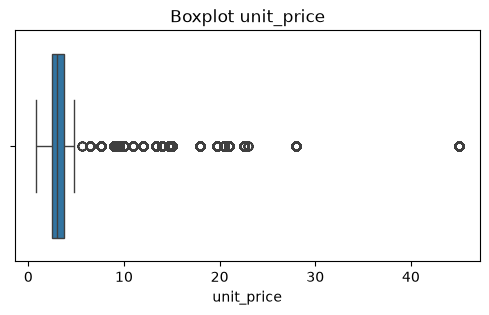

In [7]:
for kolom in ["transaction_qty", "unit_price", "Total_Bill"]:
    q1, q3 = df[kolom].quantile([0.25, 0.75])   # kuartil 1 dan 3
    iqr = q3 - q1                                # selisih Q3 - Q1
    batas_bawah = q1 - 1.5 * iqr
    batas_atas  = q3 + 1.5 * iqr
    jumlah = ((df[kolom] < batas_bawah) | (df[kolom] > batas_atas)).sum()
    print(f"{kolom}: {jumlah} outlier (batas {batas_bawah:.2f} - {batas_atas:.2f})")

plt.figure(figsize=(6, 3))
sns.boxplot(x=df["unit_price"])
plt.title("Boxplot unit_price")
plt.show()

## 4. Transformasi Data

In [8]:
print("Total_Bill == qty x harga:",
      (df["transaction_qty"] * df["unit_price"] == df["Total_Bill"]).mean())
print(pd.crosstab(df["Month"], df["Month Name"]))

Total_Bill == qty x harga: 0.996781029534054
Month Name  April  February  January   June  March    May
Month                                                    
1               0         0    17314      0      0      0
2               0     16359        0      0      0      0
3               0         0        0      0  21229      0
4           25335         0        0      0      0      0
5               0         0        0      0      0  33527
6               0         0        0  35352      0      0


In [9]:
fitur = ["store_location", "transaction_qty", "Size", "Hour", "Month", "Day of Week"]
X = df[fitur]
y = df["product_category"]

print("Bentuk X:", X.shape)
print("Bentuk y:", y.shape)
X.head()

Bentuk X: (149116, 6)
Bentuk y: (149116,)


,store_location,transaction_qty,Size,Hour,Month,Day of Week
0,Astoria,1,Large,11,6,3
1,Astoria,1,Large,11,6,4
2,Astoria,1,Large,12,6,4
3,Astoria,1,Large,19,6,4
4,Astoria,1,Large,12,6,5


In [10]:
X = pd.get_dummies(X, columns=["store_location", "Size"], dtype=int)

print("Bentuk X setelah encoding:", X.shape)
print(list(X.columns))
X.head()

Bentuk X setelah encoding: (149116, 11)
['transaction_qty', 'Hour', 'Month', 'Day of Week', 'store_location_Astoria', "store_location_Hell's Kitchen", 'store_location_Lower Manhattan', 'Size_Large', 'Size_Not Defined', 'Size_Regular', 'Size_Small']


,transaction_qty,Hour,Month,Day of Week,store_location_Astoria,store_location_Hell's Kitchen,store_location_Lower Manhattan,Size_Large,Size_Not Defined,Size_Regular,Size_Small
0,1,11,6,3,1,0,0,1,0,0,0
1,1,11,6,4,1,0,0,1,0,0,0
2,1,12,6,4,1,0,0,1,0,0,0
3,1,19,6,4,1,0,0,1,0,0,0
4,1,12,6,5,1,0,0,1,0,0,0


## 5. EDA dan ExDA

product_category
Coffee                58416
Tea                   45449
Bakery                22796
Drinking Chocolate    11468
Flavours               6790
Coffee beans           1753
Loose Tea              1210
Branded                 747
Packaged Chocolate      487
Name: count, dtype: int64

Size
Regular        45789
Large          44885
Not Defined    44518
Small          13924
Name: count, dtype: int64


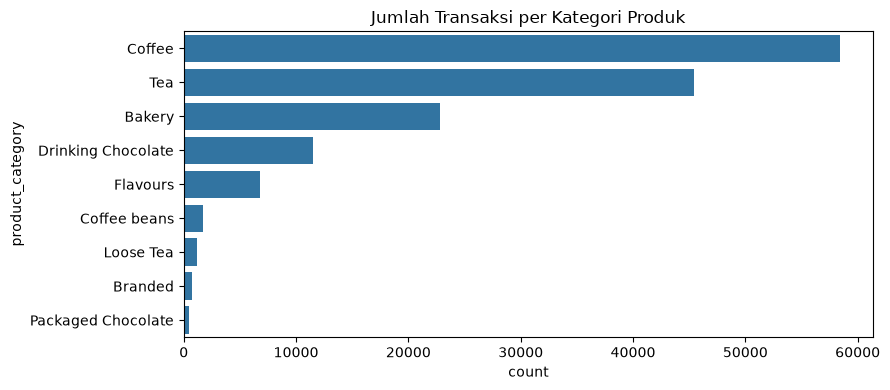

In [11]:
print(df["product_category"].value_counts())
print()
print(df["Size"].value_counts())

plt.figure(figsize=(9, 4))
sns.countplot(data=df, y="product_category",
              order=df["product_category"].value_counts().index)
plt.title("Jumlah Transaksi per Kategori Produk")
plt.tight_layout()
plt.show()

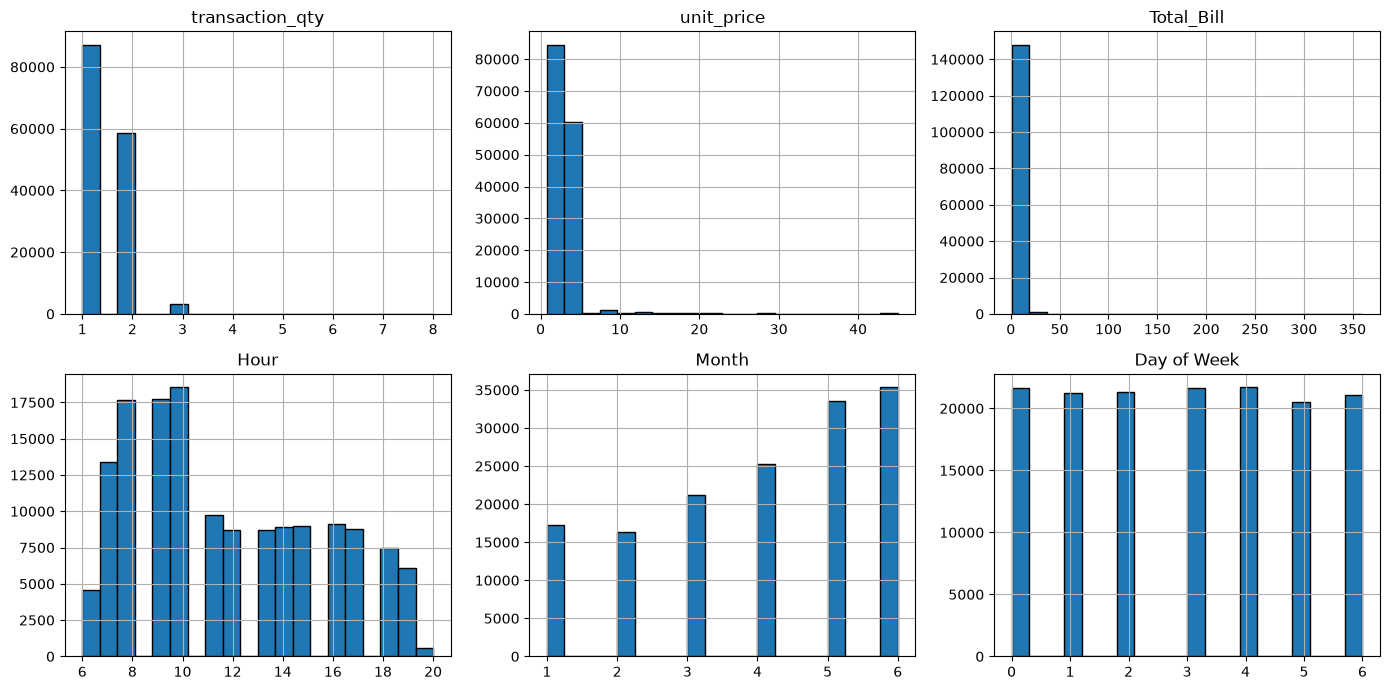

In [12]:
kolom_numerik = ["transaction_qty", "unit_price", "Total_Bill", "Hour", "Month", "Day of Week"]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, kolom in zip(axes.ravel(), kolom_numerik):
    df[kolom].hist(ax=ax, bins=20, edgecolor="black")
    ax.set_title(kolom)
plt.tight_layout()
plt.show()

transaction_qty     0.80
unit_price          8.46
Total_Bill         41.75
Hour                0.41
Month              -0.41
Day of Week         0.01
dtype: float64


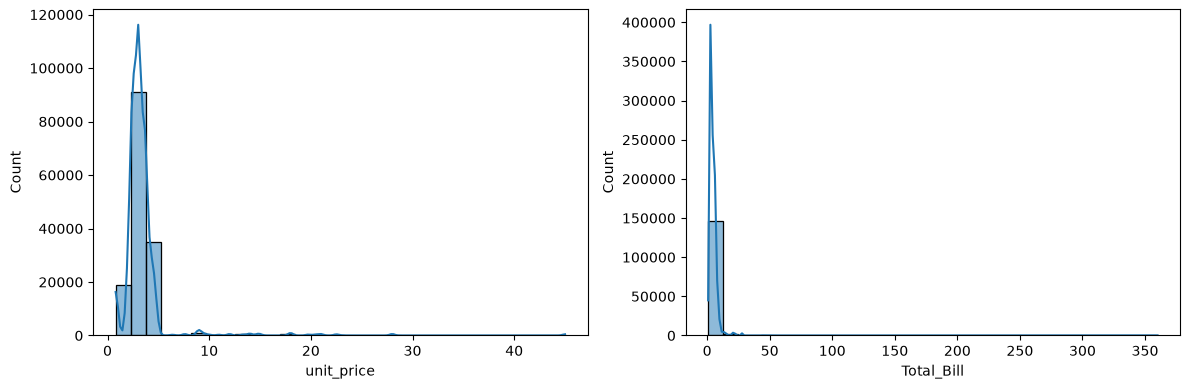

In [13]:
print(df[kolom_numerik].skew().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["unit_price"], kde=True, bins=30, ax=axes[0])
sns.histplot(df["Total_Bill"], kde=True, bins=30, ax=axes[1])
plt.tight_layout()
plt.show()

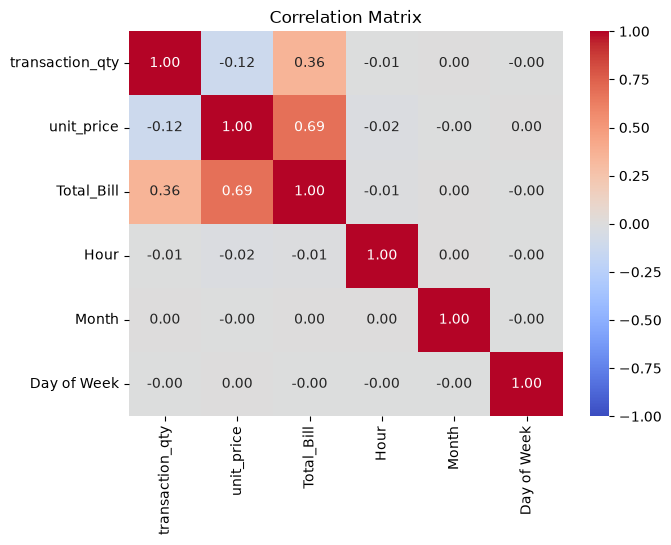

In [14]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[kolom_numerik].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.show()

In [15]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_encoded = le.fit_transform(y)
print(dict(zip(le.classes_, range(len(le.classes_)))))

korelasi_target = X.assign(target=y_encoded).corr()["target"].drop("target")
print(korelasi_target.sort_values(key=abs, ascending=False).round(3))

{'Bakery': 0, 'Branded': 1, 'Coffee': 2, 'Coffee beans': 3, 'Drinking Chocolate': 4, 'Flavours': 5, 'Loose Tea': 6, 'Packaged Chocolate': 7, 'Tea': 8}
Size_Not Defined                 -0.488
Size_Regular                      0.311
Size_Large                        0.301
Size_Small                       -0.200
transaction_qty                   0.189
store_location_Astoria            0.017
store_location_Lower Manhattan   -0.016
Hour                              0.014
Day of Week                       0.001
store_location_Hell's Kitchen    -0.001
Month                            -0.000
Name: target, dtype: float64


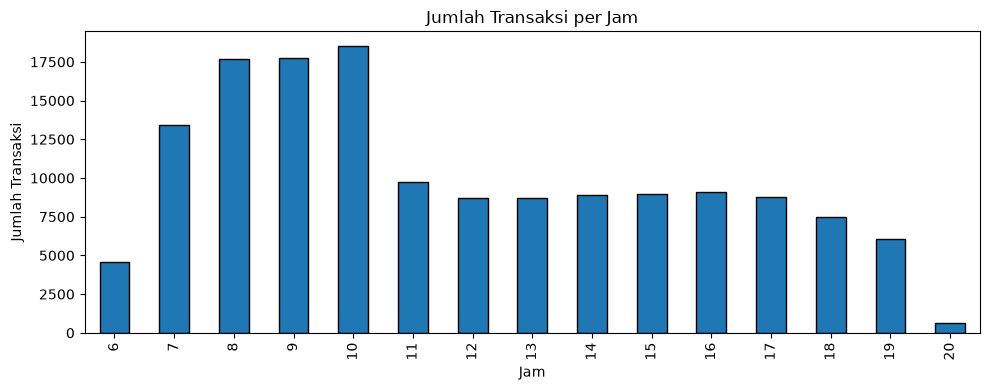

In [16]:
per_jam = df.groupby("Hour").size()

plt.figure(figsize=(10, 4))
per_jam.plot(kind="bar", edgecolor="black")
plt.title("Jumlah Transaksi per Jam")
plt.xlabel("Jam")
plt.ylabel("Jumlah Transaksi")
plt.tight_layout()
plt.show()

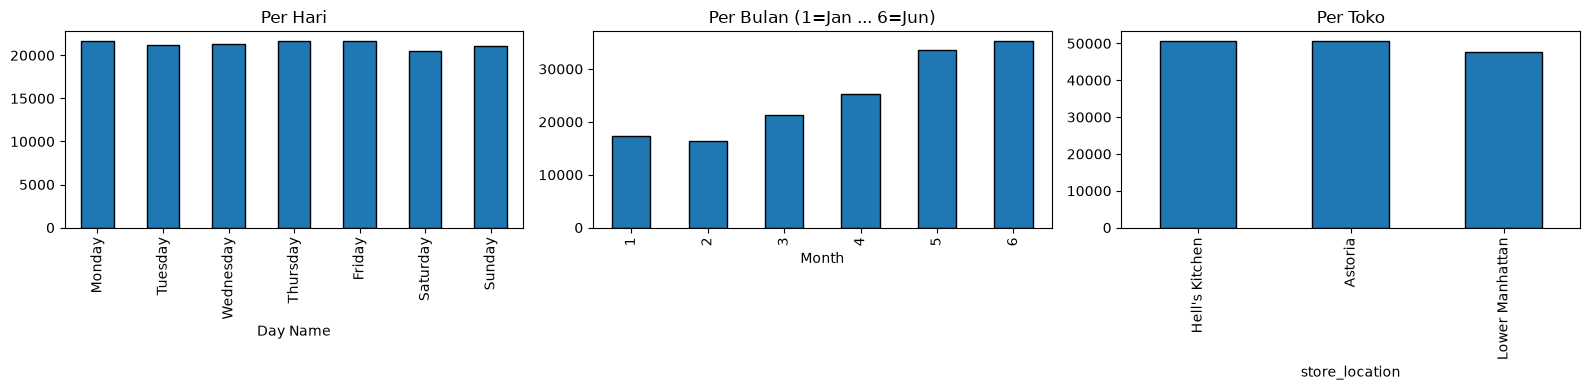

In [17]:
urutan_hari = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df["Day Name"].value_counts().reindex(urutan_hari).plot(kind="bar", ax=axes[0], edgecolor="black")
axes[0].set_title("Per Hari")
df["Month"].value_counts().sort_index().plot(kind="bar", ax=axes[1], edgecolor="black")
axes[1].set_title("Per Bulan (1=Jan ... 6=Jun)")
df["store_location"].value_counts().plot(kind="bar", ax=axes[2], edgecolor="black")
axes[2].set_title("Per Toko")
plt.tight_layout()
plt.show()

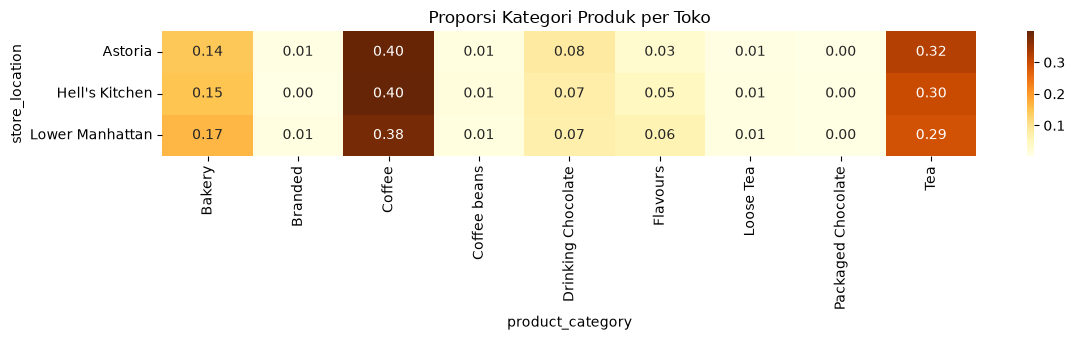

In [18]:
komposisi = pd.crosstab(df["store_location"], df["product_category"], normalize="index")

plt.figure(figsize=(12, 3.5))
sns.heatmap(komposisi, annot=True, fmt=".2f", cmap="YlOrBr")
plt.title("Proporsi Kategori Produk per Toko")
plt.tight_layout()
plt.show()

### 6. Data Splitting

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

# cek: proporsi kategori harus hampir sama di ketiga kolom
proporsi = pd.concat(
    [y.value_counts(normalize=True),
     y_train.value_counts(normalize=True),
     y_test.value_counts(normalize=True)],
    axis=1, keys=["Semua", "Train", "Test"]
).round(4)
print()
print(proporsi)

X_train: (119292, 11)
X_test : (29824, 11)
y_train: (119292,)
y_test : (29824,)

                     Semua   Train    Test
product_category                          
Coffee              0.3917  0.3917  0.3918
Tea                 0.3048  0.3048  0.3048
Bakery              0.1529  0.1529  0.1529
Drinking Chocolate  0.0769  0.0769  0.0769
Flavours            0.0455  0.0455  0.0455
Coffee beans        0.0118  0.0118  0.0118
Loose Tea           0.0081  0.0081  0.0081
Branded             0.0050  0.0050  0.0050
Packaged Chocolate  0.0033  0.0033  0.0033


In [20]:
from sklearn.preprocessing import StandardScaler

kolom_angka = ["transaction_qty", "Hour", "Month", "Day of Week"]

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled  = X_test.copy()

X_train_scaled[kolom_angka] = scaler.fit_transform(X_train[kolom_angka])  # fit + transform di train
X_test_scaled[kolom_angka]  = scaler.transform(X_test[kolom_angka])       # transform saja di test

print(X_train_scaled[kolom_angka].mean().round(3))
print(X_train_scaled[kolom_angka].std().round(3))

transaction_qty    0.0
Hour              -0.0
Month             -0.0
Day of Week       -0.0
dtype: float64
transaction_qty    1.0
Hour               1.0
Month              1.0
Day of Week        1.0
dtype: float64


In [21]:
from sklearn import tree
from sklearn.model_selection import cross_val_score

clf = tree.DecisionTreeClassifier(random_state=42)   # model Decision Tree sederhana
scores = cross_val_score(clf, X_train, y_train, cv=5) # 5-fold cross validation

print("Akurasi tiap fold:", scores.round(4))
print("Rata-rata        :", scores.mean().round(4))
print("Standar deviasi  :", scores.std().round(4))

Akurasi tiap fold: [0.54   0.5416 0.5359 0.5417 0.5379]
Rata-rata        : 0.5394
Standar deviasi  : 0.0022


In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Model 1: Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_scaled, y_train)

# Model 2: Decision Tree
dt = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)

# Model 3: Random Forest
rf = RandomForestClassifier(random_state=42, n_jobs=-1).fit(X_train, y_train)

print("Ketiga model selesai dilatih")

Ketiga model selesai dilatih


In [23]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Prediksi pada data uji
pred_lr = lr.predict(X_test_scaled)
pred_dt = dt.predict(X_test)
pred_rf = rf.predict(X_test)

def hitung_metrik(y_asli, y_prediksi):
    return [
        accuracy_score(y_asli, y_prediksi),
        precision_score(y_asli, y_prediksi, average="weighted", zero_division=0),
        recall_score(y_asli, y_prediksi, average="weighted", zero_division=0),
        f1_score(y_asli, y_prediksi, average="weighted", zero_division=0),
    ]

# Simpan hasil ke tabel (DataFrame), seperti contoh di materi
df_hasil = pd.DataFrame(
    [hitung_metrik(y_test, pred_lr),
     hitung_metrik(y_test, pred_dt),
     hitung_metrik(y_test, pred_rf)],
    columns=["Accuracy", "Precision", "Recall", "F1-score"],
    index=["Logistic Regression", "Decision Tree", "Random Forest"]
)
df_hasil.round(4)

,Accuracy,Precision,Recall,F1-score
Logistic Regression,0.5813,0.6013,0.5813,0.5063
Decision Tree,0.5436,0.5087,0.5436,0.5060
Random Forest,0.5455,0.5048,0.5455,0.5069


In [24]:
from sklearn.metrics import classification_report

semua_prediksi = {"Logistic Regression": pred_lr, "Decision Tree": pred_dt, "Random Forest": pred_rf}
nama_terbaik = df_hasil["Accuracy"].idxmax()
print("Model terpilih:", nama_terbaik)
print()
print(classification_report(y_test, semua_prediksi[nama_terbaik], zero_division=0))

Model terpilih: Logistic Regression

                    precision    recall  f1-score   support

            Bakery       0.63      0.98      0.77      4559
           Branded       0.00      0.00      0.00       149
            Coffee       0.84      0.31      0.46     11684
      Coffee beans       0.00      0.00      0.00       351
Drinking Chocolate       0.00      0.00      0.00      2294
          Flavours       0.50      0.09      0.15      1358
         Loose Tea       0.00      0.00      0.00       242
Packaged Chocolate       0.00      0.00      0.00        97
               Tea       0.50      1.00      0.67      9090

          accuracy                           0.58     29824
         macro avg       0.27      0.26      0.23     29824
      weighted avg       0.60      0.58      0.51     29824



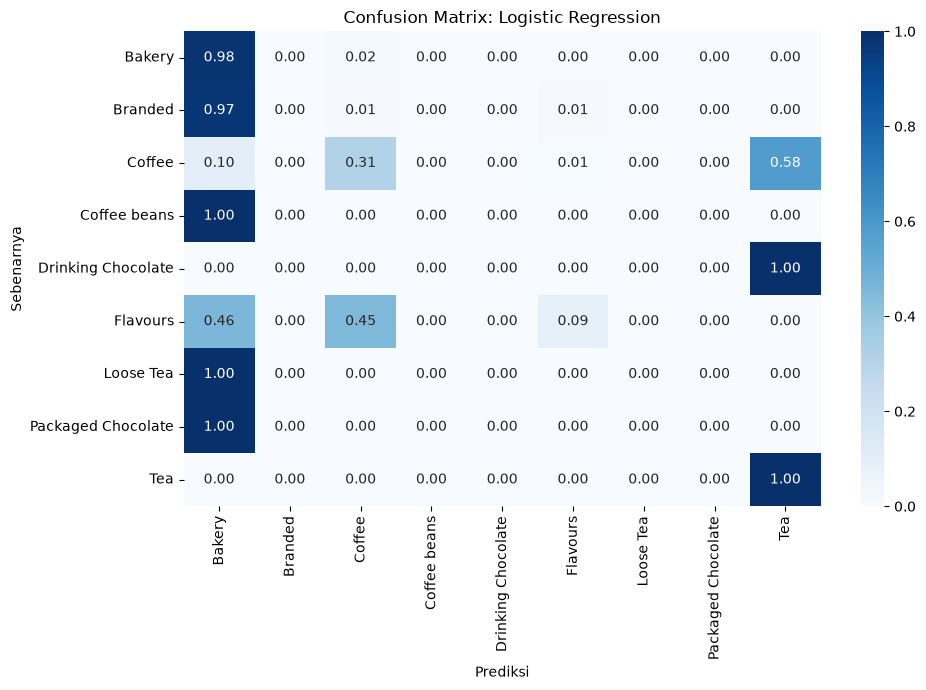

In [25]:
from sklearn.metrics import confusion_matrix

kelas = sorted(y.unique())
cm = confusion_matrix(y_test, semua_prediksi[nama_terbaik], labels=kelas, normalize="true")

plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=kelas, yticklabels=kelas)
plt.xlabel("Prediksi")
plt.ylabel("Sebenarnya")
plt.title(f"Confusion Matrix: {nama_terbaik}")
plt.tight_layout()
plt.show()

In [26]:
import joblib, os

joblib.dump(lr, "model_logistic_regression.joblib")
joblib.dump(scaler, "scaler.joblib")

for nama in ["model_logistic_regression.joblib", "scaler.joblib"]:
    print(nama, "->", round(os.path.getsize(nama) / 1024, 1), "KB")

model_logistic_regression.joblib -> 2.3 KB
scaler.joblib -> 0.9 KB


### 7.deployment

In [27]:
from sklearn.ensemble import RandomForestClassifier

# Menginisialisasi model Random Forest
# random_state=42 digunakan agar hasil pelatihan konsisten
model_rf = RandomForestClassifier(n_estimators=100, random_state=42)

# Melatih model menggunakan data latih
print("Sedang melatih model...")
model_rf.fit(X_train, y_train)
print("Pelatihan model selesai!")

Sedang melatih model...
Pelatihan model selesai!


In [28]:
from sklearn.metrics import accuracy_score, classification_report

# Meminta model memprediksi data uji
y_pred = model_rf.predict(X_test)

# Menghitung metrik evaluasi
akurasi = accuracy_score(y_test, y_pred)
print(f"Akurasi Model: {akurasi * 100:.2f}%\n")

print("--- Laporan Klasifikasi Lengkap ---")
print(classification_report(y_test, y_pred))

Akurasi Model: 54.55%

--- Laporan Klasifikasi Lengkap ---


C:\Users\iqsa\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\iqsa\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


                    precision    recall  f1-score   support

            Bakery       0.63      0.96      0.76      4559
           Branded       0.08      0.01      0.01       149
            Coffee       0.57      0.47      0.51     11684
      Coffee beans       0.33      0.00      0.01       351
Drinking Chocolate       0.13      0.02      0.03      2294
          Flavours       0.44      0.20      0.28      1358
         Loose Tea       0.00      0.00      0.00       242
Packaged Chocolate       0.00      0.00      0.00        97
               Tea       0.50      0.67      0.57      9090

          accuracy                           0.55     29824
         macro avg       0.30      0.26      0.24     29824
      weighted avg       0.50      0.55      0.51     29824



C:\Users\iqsa\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [29]:
import joblib

# Menyimpan model yang sudah dilatih ke dalam file
nama_file_model = 'model_rf_siap_deploy.pkl'
joblib.dump(model_rf, nama_file_model)

print(f"Model berhasil disimpan sebagai: {nama_file_model}")
print("File ini siap diunggah ke server untuk Deployment.")

Model berhasil disimpan sebagai: model_rf_siap_deploy.pkl
File ini siap diunggah ke server untuk Deployment.


In [30]:
import logging
import pandas as pd

# Konfigurasi sistem logging untuk mencatat ke file 'monitoring_model.log'
logging.basicConfig(
    filename='monitoring_model.log', 
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s'
)

def prediksi_dan_monitor(data_baru, model_terlatih):
    """
    Fungsi simulasi untuk menerima data baru, memprediksi, dan mencatat log (monitoring).
    """
    try:
        # Melakukan prediksi
        hasil_prediksi = model_terlatih.predict(data_baru)
        
        # Mencatat (logging) aktivitas ke dalam file pemantauan
        for i, hasil in enumerate(hasil_prediksi):
            pesan_log = f"Data Input Index-{i} berhasil diproses. Prediksi Kelas: {hasil}"
            logging.info(pesan_log)
            print(pesan_log)
            
        return hasil_prediksi
        
    except Exception as e:
        # Mencatat jika terjadi error/anomali data (Error Monitoring)
        logging.error(f"Terjadi kesalahan saat prediksi: {e}")

# Simulasi: Memuat ulang model yang sudah di-deploy dan mengujinya dengan 2 data baru
model_produksi = joblib.load('model_rf_siap_deploy.pkl')
data_simulasi_baru = X_test.iloc[:2] # Mengambil 2 baris data uji sebagai contoh data baru

print("\n--- Memulai Simulasi Deployment & Monitoring ---")
prediksi_dan_monitor(data_simulasi_baru, model_produksi)
print("Catatan monitoring telah disimpan di file 'monitoring_model.log'.")


--- Memulai Simulasi Deployment & Monitoring ---
Data Input Index-0 berhasil diproses. Prediksi Kelas: Coffee
Data Input Index-1 berhasil diproses. Prediksi Kelas: Coffee
Catatan monitoring telah disimpan di file 'monitoring_model.log'.


## Selesai
Pengerjaan berhenti di **Data modeling** sesuai ketentuan tugas.  
Pelatihan dan evaluasi model tidak dikerjakan di project ini.